In [1]:
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

# Hodnoty z DS 7
n_per_group = 3839    # ← doplň svoje n z DS 7
p1 = 0.10             # baseline konverzný pomer
alpha = 0.05
n_simulations = 10_000

np.random.seed(42)
print(f"n = {n_per_group}, p = {p1}, simulácií = {n_simulations:,}")

n = 3839, p = 0.1, simulácií = 10,000


In [2]:
p_values = []

for _ in range(n_simulations):
    control   = np.random.binomial(1, p1, n_per_group)
    treatment = np.random.binomial(1, p1, n_per_group)  # rovnaký pomer!
    _, p = stats.ttest_ind(control, treatment)
    p_values.append(p)

fpr = sum(p < alpha for p in p_values) / n_simulations
print(f"False Positive Rate: {fpr:.3f}  (očakávané: ~0.050)")

False Positive Rate: 0.050  (očakávané: ~0.050)


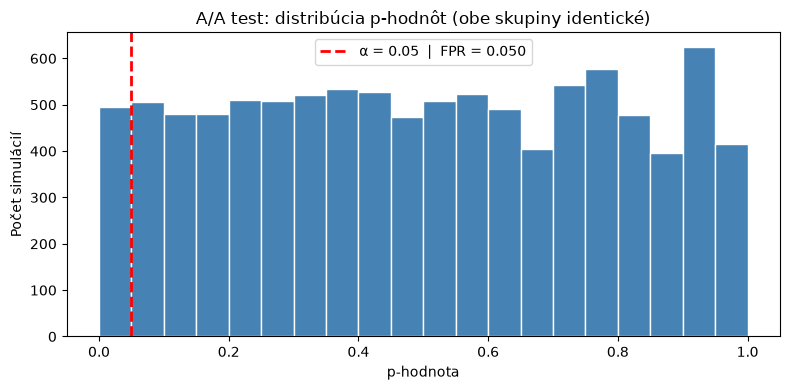

In [3]:
plt.figure(figsize=(8, 4))
plt.hist(p_values, bins=20, edgecolor='white', color='steelblue')
plt.axvline(x=0.05, color='red', linestyle='--', linewidth=2, label=f'α = 0.05  |  FPR = {fpr:.3f}')
plt.xlabel('p-hodnota')
plt.ylabel('Počet simulácií')
plt.title('A/A test: distribúcia p-hodnôt (obe skupiny identické)')
plt.legend()
plt.tight_layout()
plt.savefig('aa_test_pvalues.png', dpi=120)
plt.show()

## Záver

- Simulovaných A/A testov: 10 000
- FPR: ~5 % → sedí na zvolenej hladine α = 0.05
- Distribúcia p-hodnôt je rovnomerná (uniform) – správne správanie testu
- Ak by FPR bol napr. 20 %, znamenalo by to chybu v implementácii testu

**Zajtra (DS 9):** čo sa stane s FPR, ak výsledky sledujeme priebežne (peeking)?

# DS9 – Peeking simulation

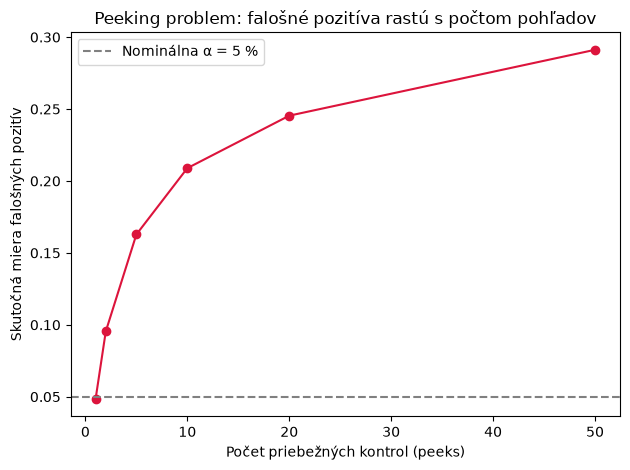

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

def simulate_peeking(n_total=1000, n_peeks=10, n_sim=10_000, alpha=0.05):
    """Vráti podiel experimentov, kde aspoň raz padne p < alpha (H0 pravdivá)."""
    check_points = np.linspace(50, n_total, n_peeks, dtype=int)
    false_positives = 0
    for _ in range(n_sim):
        data_A = np.random.normal(0, 1, n_total)
        data_B = np.random.normal(0, 1, n_total)  # žiadny skutočný efekt
        for cp in check_points:
            _, p = stats.ttest_ind(data_A[:cp], data_B[:cp])
            if p < alpha:
                false_positives += 1
                break   # stačí jedna falošná detekcia
    return false_positives / n_sim

# Spusti pre rôzny počet priebežných kontrol
peek_counts = [1, 2, 5, 10, 20, 50]
fp_rates = [simulate_peeking(n_peeks=k) for k in peek_counts]

plt.plot(peek_counts, fp_rates, 'o-', color='crimson')
plt.axhline(0.05, linestyle='--', color='gray', label='Nominálna α = 5 %')
plt.xlabel('Počet priebežných kontrol (peeks)')
plt.ylabel('Skutočná miera falošných pozitív')
plt.title('Peeking problem: falošné pozitíva rastú s počtom pohľadov')
plt.legend(); plt.tight_layout(); plt.savefig('peeking_curve.png', dpi=120)

Pri jedinom pohľade = 5 % FP. Pri 20 priebežných kontrolách = ~25 % FP. Záver: peeking výrazne nafukuje chybu 1. druhu.